# Stock price forecasting using LOB

Before start, we need to test some libraries in order to build a reasonable dataset for the neural network architecture. Test will be focused on libraries for crypto market data and stock market data. For more corporate indices (bank indices) maybe there are other libraries to test in a second moment.

### Import modules

In [12]:
import os
import sys
import time 
import pandas
import random
import pickle
from tqdm import tqdm
import numpy as np

# ML
import pandas as pd
from matplotlib import pyplot as plt
from sklearn import preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.metrics import r2_score, roc_auc_score
from sklearn.preprocessing import LabelBinarizer, OneHotEncoder

# pytorch
import torch.nn as nn
import torch
import torch.nn.functional as F
import json, argparse
import torchvision
import torchvision.transforms as transforms
import torch.optim as optim
import torch.utils

# software modules
import build_timeseries
import neural_networks
import LSTM
import utils
import CNN_LSTM
import deeplob

### Load LOB data

In [13]:
dataset = pd.read_parquet('./FI-2010/WRT1V/WRT1V_10.parquet', engine='pyarrow')
dataset = dataset[:]
# compute the price with the 1st level of the LOB and add the column to the dataset
#dataset['mid_price'] = (dataset['P_Ask_1'] + dataset['P_Bid_1']) / 2
#dataset['weighted_price'] = (dataset['P_Ask_1']*dataset['V_Ask_1'] + dataset['P_Bid_1']*dataset['V_Bid_1']) / (dataset['V_Ask_1']+dataset['V_Bid_1'])
target_columns = dataset['Label'].astype(int)
dataset = dataset.drop('Label', axis=1)
dataset = dataset.drop('Day', axis=1)
display(dataset)

#plt.figure(figsize=(24,12))
#plt.plot(dataset['mid_price'])
#plt.show()

#target_columns = (dataset['P_Ask_1'] + dataset['P_Bid_1']) / 2

,P_Ask_1,V_Ask_1,P_Bid_1,V_Bid_1,P_Ask_2,V_Ask_2,P_Bid_2,V_Bid_2,P_Ask_3,V_Ask_3,...,P_Bid_8,V_Bid_8,P_Ask_9,V_Ask_9,P_Bid_9,V_Bid_9,P_Ask_10,V_Ask_10,P_Bid_10,V_Bid_10
0,1.242406,-0.611621,1.240199,-0.446819,1.241779,-0.663252,1.240732,-0.512393,1.241182,-0.770717,...,1.242047,-0.349285,1.238846,-0.418570,1.243297,-0.499588,1.236425,-0.444236,1.243820,-0.278126
1,1.241385,-0.678429,1.240199,-0.555044,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,1.244095,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846
2,1.241385,-0.678429,1.240199,-0.465970,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,1.244095,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846
3,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,1.244095,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846
4,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,1.244095,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
147150,1.462738,-0.030648,1.467926,-0.197623,1.462118,-0.401187,1.465580,-0.569871,1.461516,-0.004800,...,1.467151,-0.607661,1.456363,-0.413108,1.467757,-0.148597,1.454553,-0.422392,1.469532,-0.239478
147151,1.462738,-0.030648,1.467926,-0.197623,1.462118,-0.401187,1.465580,-0.623560,1.461516,-0.004800,...,1.467151,-0.607661,1.456363,-0.413108,1.467757,-0.148597,1.454553,-0.422392,1.469532,-0.239478
147152,1.462738,-0.030648,1.467926,-0.197623,1.462118,-0.401187,1.465580,-0.677249,1.461516,-0.004800,...,1.468135,-0.483058,1.456363,-0.413108,1.469725,-0.516647,1.454553,-0.422392,1.470517,-0.186564
147153,1.462738,-0.030648,1.467926,-0.197623,1.462118,-0.401187,1.466562,-0.737917,1.461516,-0.004800,...,1.468135,-0.483058,1.456363,-0.413108,1.469725,-0.516647,1.454553,-0.422392,1.470517,-0.186564


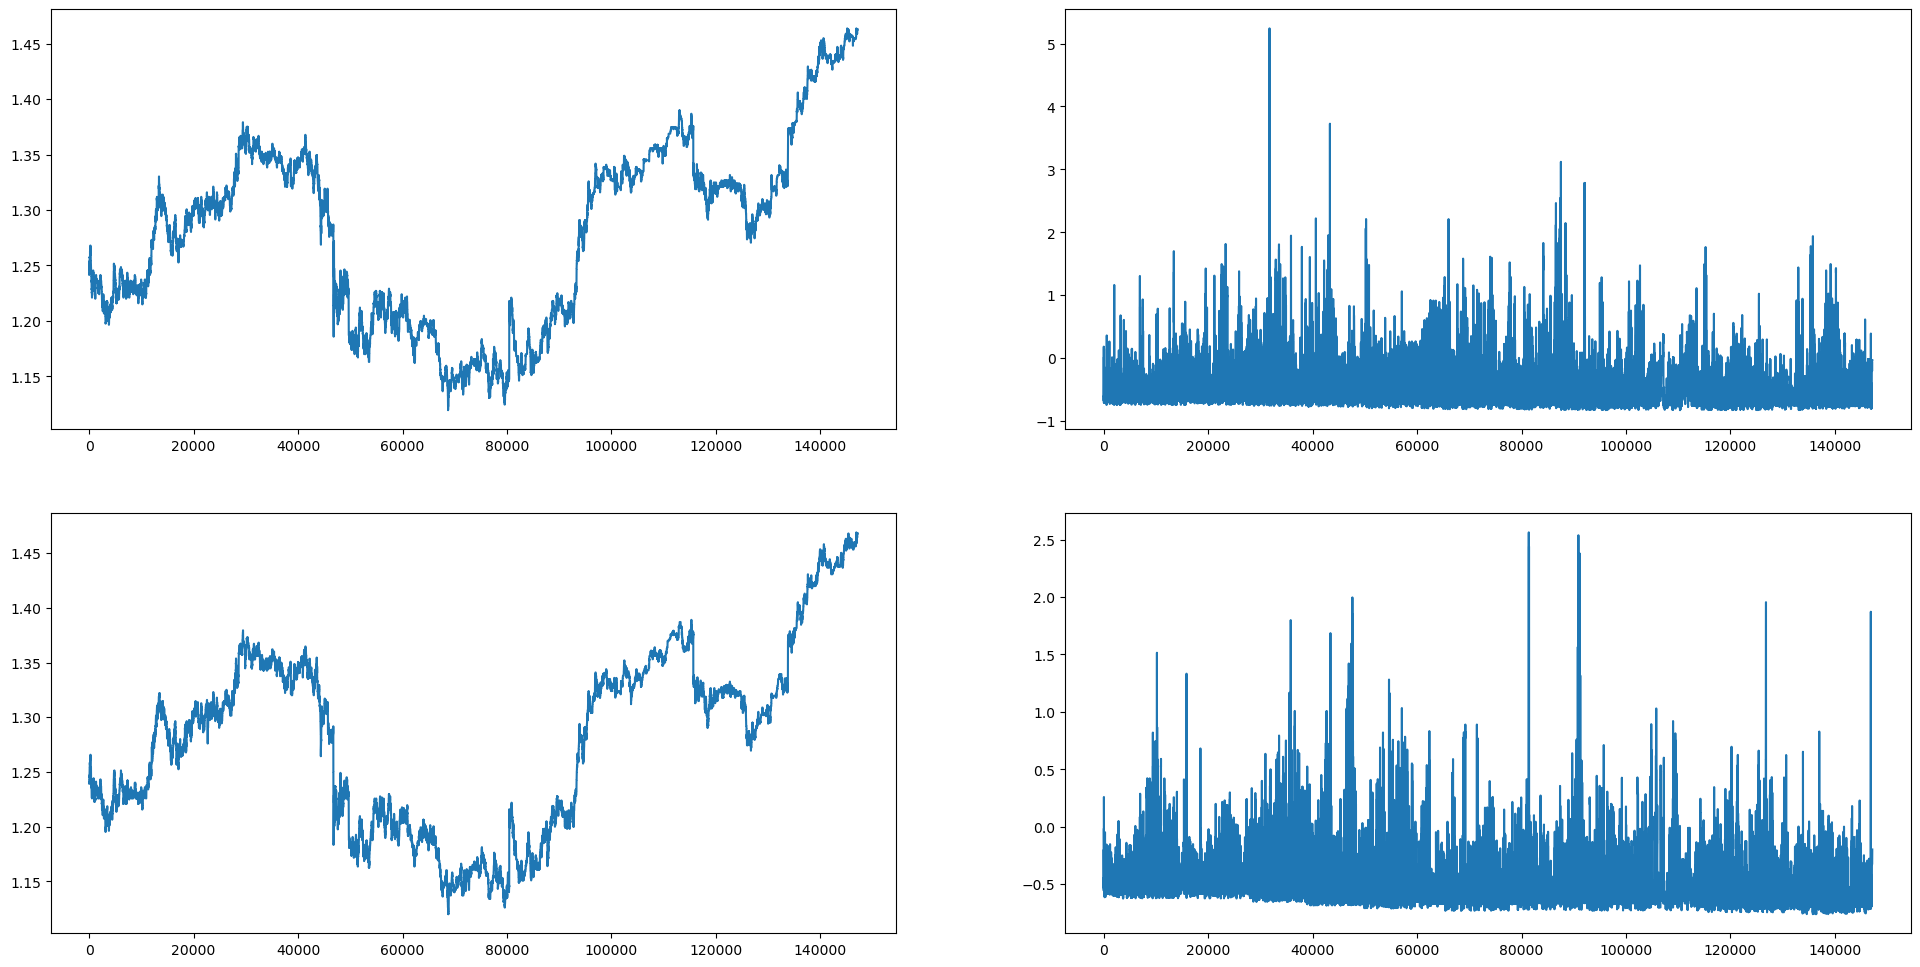

In [14]:
_, axs = plt.subplots(2, 2, figsize=(24,12))
axs[0,0].plot(dataset['P_Ask_1'])
axs[0,1].plot(dataset['V_Ask_1'])
axs[1,0].plot(dataset['P_Bid_1'])
axs[1,1].plot(dataset['V_Bid_1'])
plt.show()

### Create the effective time-series dataset, and the batch-iterators to process tensors

The procedure is the sliding window procedure

In [11]:
#device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")

# the final time-series dataset
lookback_period = 10
# Remember to reshape the arrays in order to get the correct tensor structure for convolution: [batch, channels, height, width]
# The standard tensor structure for LSTM layers is [batch, lookback_period, number of features] = [batch, height, width]
Dataset  =  build_timeseries.SlidingWindowDataset(	raw_dataset = dataset, 
													split_rate = 0.7,
													#target_columns = target_columns,
													#target_columns = ['mid_price'],
													target_columns = ['P_Ask_1', 'V_Ask_1', 'P_Bid_1', 'V_Bid_1'],
													lookback_period = lookback_period,
													prediction_horizon = 1,
													channels = False
												)
# in the following lines the features are transformed into torch tensors, within the train and test loaders
trainset =  build_timeseries.CreateLoader(dataset = Dataset.train, transform = None)
testset  =  build_timeseries.CreateLoader(dataset = Dataset.valid, transform = None)
print('Tabelle nel trainset:', len(trainset))
print('Tabelle nel testset :', len(testset))

# dataloaders -> the batch dimension is added as first
trainloader = torch.utils.data.DataLoader(dataset=trainset, batch_size=32, shuffle=False, drop_last=False)
testloader  = torch.utils.data.DataLoader(dataset=testset,  batch_size=32, shuffle=False, drop_last=False)
print(next(iter(trainloader))[0].shape, next(iter(trainloader))[1].shape)
display(pd.DataFrame(next(iter(trainloader))[0][0]))
display(pd.DataFrame(next(iter(trainloader))[1][0]))

Tabelle nel trainset: 103001
Tabelle nel testset : 44144
torch.Size([32, 10, 40]) torch.Size([32, 1, 4])


,0,1,2,3,4,5,6,7,8,9,...,30,31,32,33,34,35,36,37,38,39
0,1.242406,-0.611621,1.240199,-0.446819,1.241779,-0.663252,1.240732,-0.512393,1.241182,-0.770717,...,1.242047,-0.349285,1.238846,-0.418570,1.243297,-0.499588,1.236425,-0.444236,1.243820,-0.278126
1,1.241385,-0.678429,1.240199,-0.555044,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,1.244095,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846
2,1.241385,-0.678429,1.240199,-0.465970,1.240758,-0.663252,1.240732,-0.608105,1.240162,-0.770717,...,1.244095,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846
3,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,1.244095,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846
4,1.241385,-0.678429,1.240199,-0.540792,1.240758,-0.663252,1.240732,-0.512393,1.240162,-0.770717,...,1.244095,-0.480323,1.234773,-0.415537,1.244322,-0.339924,1.233373,-0.228680,1.245871,-0.448846
5,1.242406,-0.611621,1.240199,-0.548364,1.241779,-0.663252,1.240732,-0.512393,1.241182,-0.770717,...,1.244095,-0.480323,1.236810,-0.208768,1.244322,-0.339924,1.235408,-0.430356,1.245871,-0.448846
6,1.242406,-0.546149,1.240199,-0.548364,1.241779,-0.548104,1.240732,-0.512393,1.241182,-0.770717,...,1.244095,-0.480323,1.238846,-0.418570,1.244322,-0.339924,1.236425,-0.444236,1.245871,-0.448846
7,1.243427,-0.611621,1.240199,-0.548364,1.242799,-0.663252,1.240732,-0.512393,1.242203,-0.613560,...,1.244095,-0.480323,1.238846,-0.418570,1.244322,-0.339924,1.236425,-0.444236,1.245871,-0.448846
8,1.243427,-0.611621,1.240199,-0.433904,1.242799,-0.663252,1.240732,-0.512393,1.243223,-0.609830,...,1.242047,-0.349285,1.238846,-0.418570,1.243297,-0.499588,1.236425,-0.444236,1.243820,-0.278126
9,1.243427,-0.611621,1.240199,-0.433904,1.242799,-0.663252,1.240732,-0.512393,1.243223,-0.609830,...,1.244095,-0.480323,1.238846,-0.292227,1.244322,-0.339924,1.236425,-0.444236,1.245871,-0.448846


,0,1,2,3
0,1.243427,-0.611621,1.239176,-0.446374


### Select the model and the parameters

In [4]:
W, H = len(dataset.columns), len(dataset)

#model = neural_networks.LSTM1(input_size=W, hidden_layer_size=64, num_layers=2, output_size=1, dropout=0.2)
#model = neural_networks.LSTM2(input_size=W, hidden_layer_size=64, num_layers=2, output_size=1, dropout=0.2)
#model = neural_networks.LSTMWithAttention(  input_size=W, 
#                                            encoder_hidden_size=64, 
#                                            encoder_layers=2, 
#                                            decoder_hidden_size=64, 
#                                            decoder_layers=2,
#                                            output_size=1,
#                                            dropout=0.2)

model = CNN_LSTM.LobCNN(lookback_period = lookback_period,
                        inner_convolutional_layers = 2,
                        smoothing_percentage = 0.06,
                        convolution_channels = 32,
                        inception_channels = 64,
                        lstm_layers = 1,
                        output_size = 3,
                        regression = False
                    )

### Train the model

In [5]:
model.to(model.device)
# Memory management on CUDA:
torch.cuda.empty_cache()

learning_rate = 0.001
epochs = 3
#LOSS = nn.MSELoss()
LOSS = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

t = 0; print("\nStart training...")
train_error = []; test_error = []
train_accuracy = []; test_accuracy = []

while t < epochs:
	model.train()
	start = time.time()
	#for i, data in enumerate(trainloader, 0):
	for inputs, labels in trainloader:
		# get the inputs; data is a list of [inputs, labels]
		#inputs, labels = data
		inputs, labels = inputs.to(model.device), labels.to(model.device)
		# zero the parameter gradients
		optimizer.zero_grad()
		outputs = model(inputs)
		#print(outputs.shape, labels.shape)
		#loss = LOSS(torch.cumsum(outputs, dim=-1), torch.cumsum(labels, dim=-1))
		labels = torch.squeeze(labels)#.type(torch.LongTensor)
		loss = LOSS(outputs, labels)
		loss.backward()
		optimizer.step()
	end = time.time()
	print(f'Tempo di calcolo epoca {t}: {end-start}, seconds')
	model.eval()
	error, accuracy = utils.get_performance(dataloader=trainloader, model=model, accname = "train_", loss=LOSS, regression=True)
	train_error.append(error); train_accuracy.append(accuracy)
	error, accuracy = utils.get_performance(dataloader=testloader, model=model, accname = "test_", loss=LOSS, regression=True)
	test_error.append(error); test_accuracy.append(accuracy)

	t += 1


Start training...


RuntimeError: Input type (double) and bias type (float) should be the same

In [ ]:
if not model.regression:
    with torch.no_grad():
        out = list(range(len(Dataset.complete)))
        features = list(range(len(Dataset.complete)))
        for i in range(len(Dataset.complete)):
            features[i] = torch.Tensor(Dataset.complete[i][0])
            features[i] = torch.unsqueeze(features[i], axis = 0)
            features[i] = features[i].to(model.device)
            out[i] = model(features[i]).cpu().squeeze().numpy()

1


In [9]:
model.to(model.device)
learning_rate = 0.001
epochs = 4
LOSS = nn.CrossEntropyLoss()
#LOSS = nn.MSELoss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

training_info = utils.batch_gd( model_id='', 
                                model=model, 
                                criterion=LOSS, 
                                optimizer=optimizer, 
                                trainloader=trainloader, 
                                testloader=testloader, 
                                epochs=epochs, 
                                regression=False, # integrate in model's fields
                                save=False)

Start training...

[--------------------------------------------------] 0.0%  starting epoch 1
torch.Size([32, 3])


RuntimeError: The size of tensor a (32) must match the size of tensor b (3) at non-singleton dimension 1

PRINT LOSS FUNCTION, AND THE ACTUAL VS PREDICTED PRICE FOR TRAIN AND TEST SETS

NameError: name 'training_info' is not defined

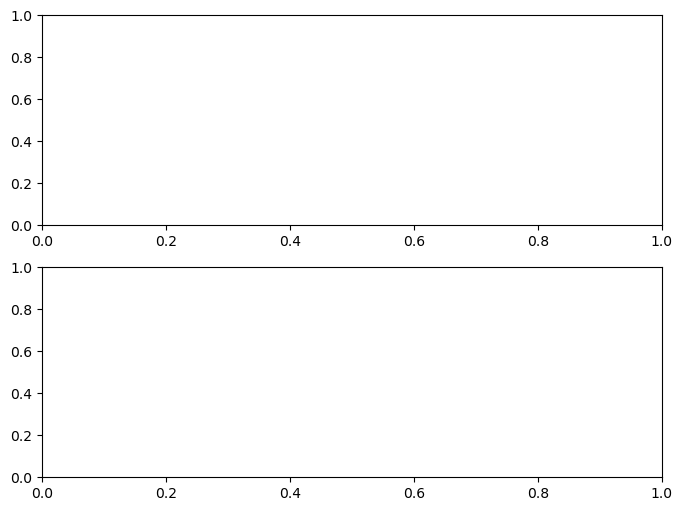

In [ ]:
epochs_list = list(range(0,epochs))
_, axs = plt.subplots(2, 1, figsize=(8,6))
axs[0].plot(epochs_list, training_info['test_loss'],  label = "test error")
axs[0].plot(epochs_list, training_info['train_loss'], label = "train error")
axs[0].legend(loc = 'best')
axs[1].plot(epochs_list, training_info['test_accuracy'],  label = "test accuracy")
axs[1].plot(epochs_list, training_info['train_accuracy'], label = "train accuracy")
axs[1].legend(loc = 'best')
plt.tight_layout()
plt.show()

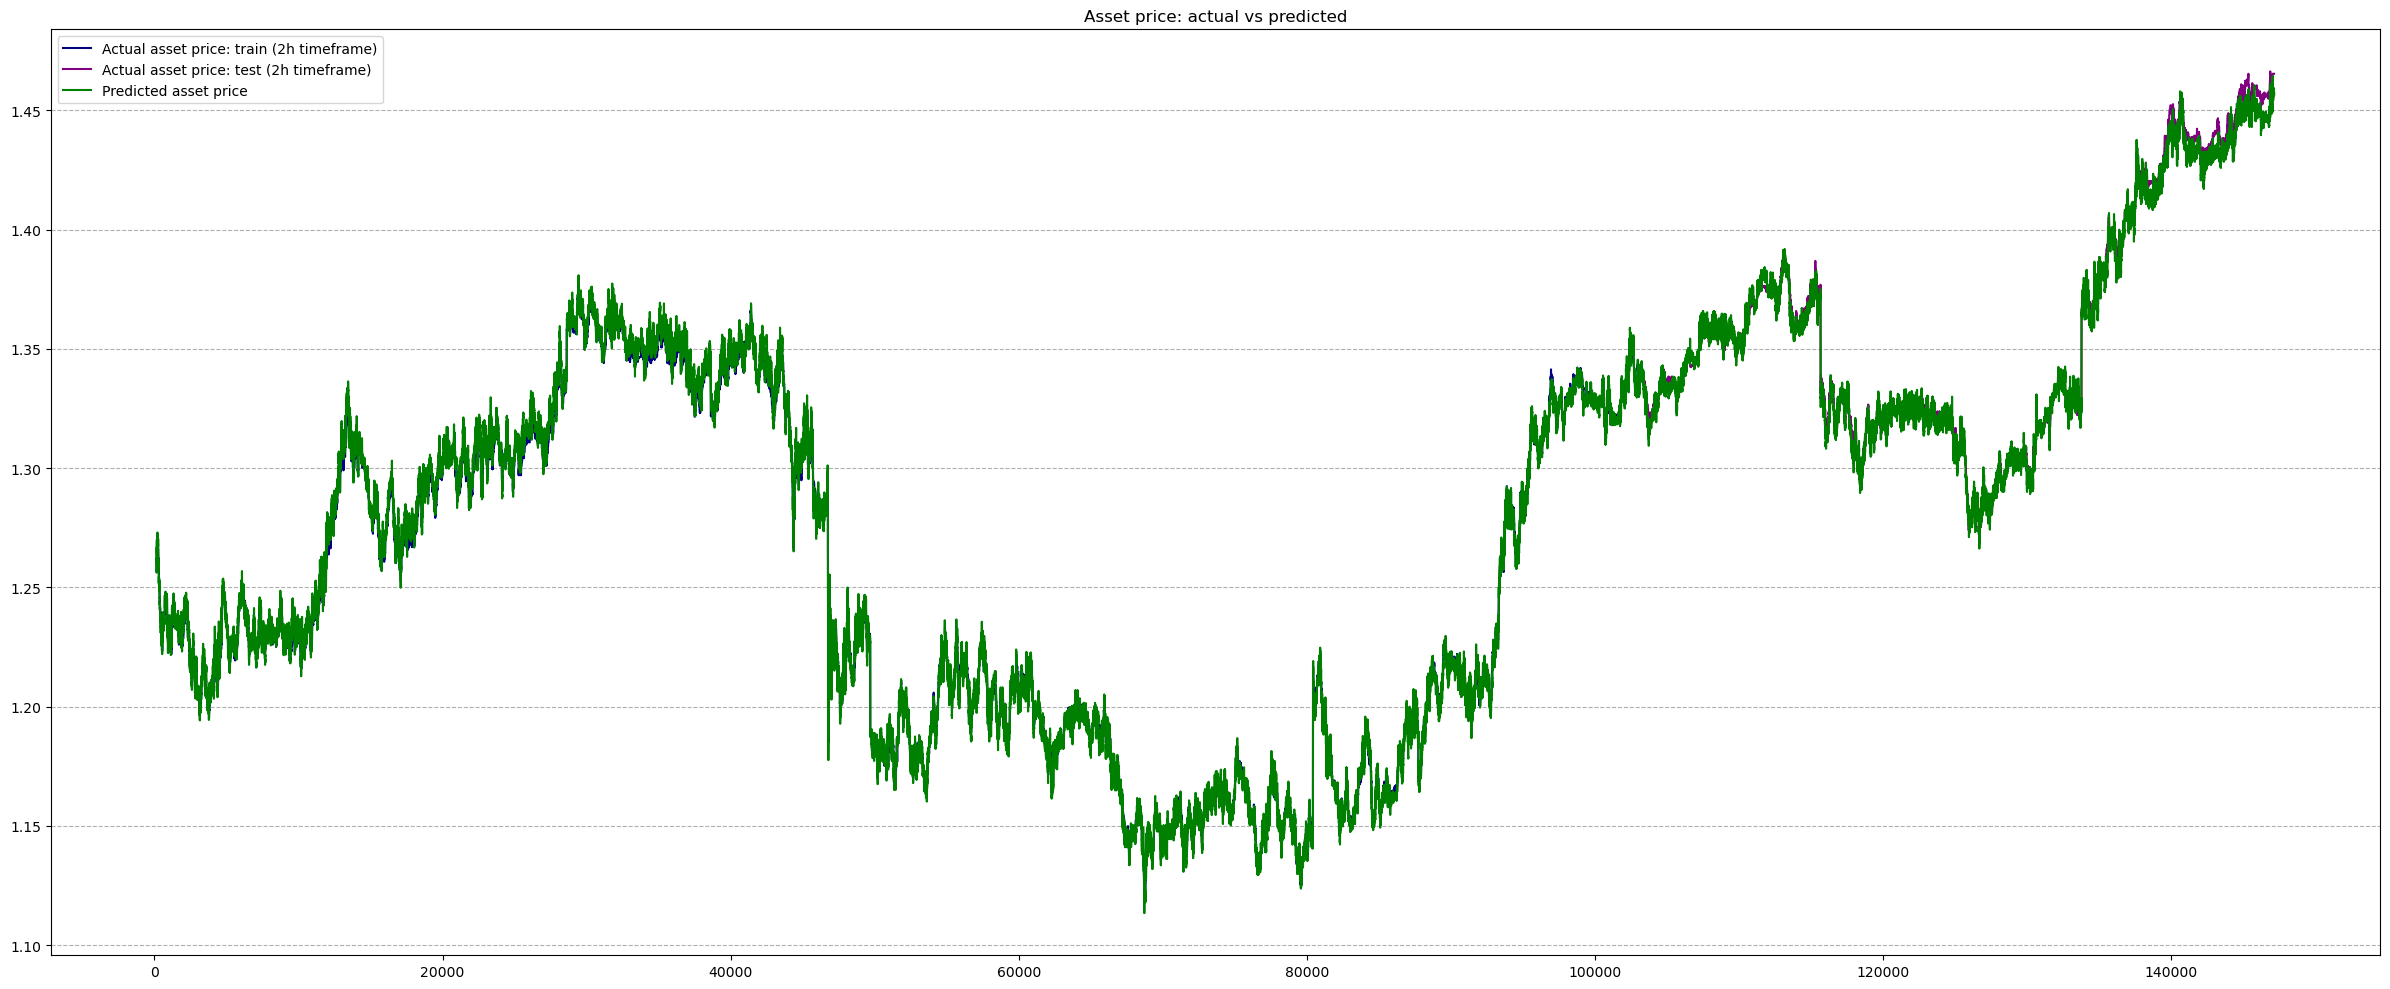

In [ ]:
with torch.no_grad():
    out = list(range(len(Dataset.complete)))
    features = list(range(len(Dataset.complete)))
    for i in range(len(Dataset.complete)):
        features[i] = torch.Tensor(Dataset.complete[i][0])
        features[i] = torch.unsqueeze(features[i], axis = 0)
        features[i] = features[i].to(model.device)
        out[i] = model(features[i]).cpu().squeeze().numpy()

targets = dataset[lookback_period:]['mid_price']

plt.figure(figsize=(24, 10))
plt.plot(targets[:int(len(targets)*0.7)], label = "Actual asset price: train (2h timeframe)", color = "navy")
plt.plot(targets[int(len(targets)*0.7):], label = "Actual asset price: test (2h timeframe)", color = "purple")
plt.plot(list(range(lookback_period,H)), out, label = "Predicted asset price", color = "green")
plt.title("Asset price: actual vs predicted")
plt.grid(visible=None, which='major', axis='y', linestyle='--')
plt.legend(loc = 'best', prop={'size': 10})
plt.tight_layout()
plt.show()